In [1]:
import os
import base64
import pandas as pd
import matplotlib.pyplot as plt

from google.auth.transport.requests import Request
from google.oauth2.credentials import Credentials
from google_auth_oauthlib.flow import InstalledAppFlow
from googleapiclient.discovery import build

In [2]:
SCOPES = ["https://www.googleapis.com/auth/gmail.readonly"]

creds = None

if os.path.exists("token.json"):
    creds = Credentials.from_authorized_user_file(
        "token.json", SCOPES
    )

if not creds or not creds.valid:

    if creds and creds.expired and creds.refresh_token:
        creds.refresh(Request())

    else:
        flow = InstalledAppFlow.from_client_secrets_file(
            "credentials.json",
            SCOPES
        )

        creds = flow.run_local_server(port=0)

    with open("token.json", "w") as token:
        token.write(creds.to_json())

Please visit this URL to authorize this application: https://accounts.google.com/o/oauth2/auth?response_type=code&client_id=285903596077-jhct240ucb81qnmp2og6pj2sjjjtd6qq.apps.googleusercontent.com&redirect_uri=http%3A%2F%2Flocalhost%3A57317%2F&scope=https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fgmail.readonly&state=4iHlAVrw05k28Li5oGStIzqCc1gMAU&code_challenge=WI4FUH-g0_08TVU78Ct4DBABP1XG4FjfDaFyqMNngB0&code_challenge_method=S256&access_type=offline


In [3]:
service = build("gmail", "v1", credentials=creds)

print("Connected to Gmail successfully!")

Connected to Gmail successfully!


In [4]:
results = service.users().messages().list(
    userId="me",
    maxResults=50,
    includeSpamTrash=True
).execute()

messages = results.get("messages", [])

print("Emails retrieved:", len(messages))

Emails retrieved: 50


In [5]:
def decode_data(data):

    if not data:
        return ""

    try:
        return base64.urlsafe_b64decode(
            data.encode("UTF-8")
        ).decode("UTF-8", errors="ignore")

    except:
        return ""

In [6]:
def get_body(payload):

    # Simple email
    if payload.get("body", {}).get("data"):
        return decode_data(payload["body"]["data"])

    # Multipart email
    parts = payload.get("parts", [])

    for part in parts:

        if part.get("mimeType") == "text/plain":
            data = part.get("body", {}).get("data")

            if data:
                return decode_data(data)

        # Search nested parts
        if part.get("parts"):
            body = get_body(part)

            if body:
                return body

    return ""

In [7]:
def get_attachments(payload):

    attachments = []

    def search_parts(parts):

        for part in parts:

            filename = part.get("filename", "")

            attachment_id = (
                part.get("body", {})
                .get("attachmentId")
            )

            if filename:

                attachments.append({
                    "filename": filename,
                    "attachment_id": attachment_id
                })

            if part.get("parts"):
                search_parts(part["parts"])

    search_parts(payload.get("parts", []))

    return attachments

In [8]:
email_data = []

In [9]:
for message in messages:

    msg = service.users().messages().get(
        userId="me",
        id=message["id"],
        format="full"
    ).execute()

    payload = msg.get("payload", {})

    headers = payload.get("headers", [])

    header_dict = {}

    for header in headers:
        header_dict[header["name"].lower()] = header["value"]

    sender = header_dict.get("from", "")
    recipient = header_dict.get("to", "")
    subject = header_dict.get("subject", "")
    date = header_dict.get("date", "")

    body = get_body(payload)

    labels = msg.get("labelIds", [])

    attachments = get_attachments(payload)

    email_data.append({

        "id": msg["id"],

        "thread_id": msg["threadId"],

        "date": date,

        "from": sender,

        "to": recipient,

        "subject": subject,

        "body": body,

        "labels": labels,

        "attachments": attachments,

        "has_attachment": len(attachments) > 0
    })

In [10]:
df = pd.DataFrame(email_data)

print(df.head())

                 id         thread_id                                   date  \
0  19fa0c9de925db2b  19fa0c9de925db2b  Sun, 26 Jul 2026 23:36:50 +0000 (UTC)   
1  19f9fc6c1b2a936e  19f9fc6c1b2a936e  Sun, 26 Jul 2026 18:53:49 +0000 (UTC)   
2  19f9c8ef30f7dd29  19f9c8ef30f7dd29        Sun, 26 Jul 2026 03:52:15 +0000   
3  19f9c362b9be7c82  19f9c362b9be7c82  Sat, 25 Jul 2026 05:24:57 +0000 (UTC)   
4  19f991d22712ebf3  19f991d22712ebf3        Sat, 25 Jul 2026 11:50:50 +0000   

                                             from  \
0                    NoBroker <hello@nobroker.in>   
1                   "Chess.com" <hello@chess.com>   
2  Shoppers Stop <ss@newsletter.shoppersstop.com>   
3              Brevistay <info@mkt.brevistay.com>   
4              MyBharat <support@mybharat.gov.in>   

                              to  \
0  null <lordhavmersi@gmail.com>   
1         lordhavmersi@gmail.com   
2       <lordhavmersi@gmail.com>   
3         lordhavmersi@gmail.com   
4         Lordhavmer

In [11]:
print(df.columns)

Index(['id', 'thread_id', 'date', 'from', 'to', 'subject', 'body', 'labels',
       'attachments', 'has_attachment'],
      dtype='str')


In [12]:
df.to_csv(
    "gmail_dataset.csv",
    index=False
)

print("Dataset saved!")

Dataset saved!


In [13]:
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicates:")
print(df.duplicated(subset="id").sum())

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id              50 non-null     str   
 1   thread_id       50 non-null     str   
 2   date            50 non-null     str   
 3   from            50 non-null     str   
 4   to              50 non-null     str   
 5   subject         50 non-null     str   
 6   body            50 non-null     str   
 7   labels          50 non-null     object
 8   attachments     50 non-null     object
 9   has_attachment  50 non-null     bool  
dtypes: bool(1), object(2), str(7)
memory usage: 1.3+ MB
None

Missing values:
id                0
thread_id         0
date              0
from              0
to                0
subject           0
body              0
labels            0
attachments       0
has_attachment    0
dtype: int64

Duplicates:
0


In [14]:
df = df.drop_duplicates(subset="id")

In [15]:
df["subject"] = df["subject"].fillna("")
df["body"] = df["body"].fillna("")
df["from"] = df["from"].fillna("")
df["to"] = df["to"].fillna("")

In [16]:
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce",
    utc=True
)

C:\Users\Fadhil\AppData\Local\Temp\ipykernel_3028\2837496913.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(


In [17]:
df = df.dropna(subset=["date"])

In [18]:
print("Total emails:", len(df))

Total emails: 50


In [19]:
top_senders = df["from"].value_counts().head(10)

print(top_senders)

from
Shoppers Stop <ss@newsletter.shoppersstop.com>    14
"Chess.com" <hello@chess.com>                      7
MyBharat <support@mybharat.gov.in>                 4
Life360 <hello@newsletter.life360.com>             4
ChatGPT <noreply@email.openai.com>                 3
Brevistay <info@mkt.brevistay.com>                 2
Spotify <no-reply@spotify.com>                     2
Quora Digest <english-quora-digest@quora.com>      2
THE FINALS <noreply@embark.email>                  2
Discord <noreply@discord.com>                      2
Name: count, dtype: int64


In [20]:
top_recipients = df["to"].value_counts().head(10)

print(top_recipients)

to
lordhavmersi@gmail.com           30
<lordhavmersi@gmail.com>         14
Lordhavmersi@gmail.com            5
null <lordhavmersi@gmail.com>     1
Name: count, dtype: int64


In [21]:
df["day"] = df["date"].dt.date

In [22]:
emails_per_day = df.groupby("day").size()

print(emails_per_day)

day
2026-06-23    3
2026-06-25    2
2026-06-26    1
2026-06-27    1
2026-06-28    2
2026-06-29    2
2026-06-30    4
2026-07-01    1
2026-07-02    1
2026-07-03    1
2026-07-04    2
2026-07-05    1
2026-07-06    1
2026-07-07    1
2026-07-09    1
2026-07-10    4
2026-07-11    3
2026-07-12    1
2026-07-13    1
2026-07-14    1
2026-07-15    1
2026-07-17    1
2026-07-18    1
2026-07-19    2
2026-07-20    1
2026-07-21    1
2026-07-23    2
2026-07-24    1
2026-07-25    3
2026-07-26    3
dtype: int64


In [23]:
attachment_emails = df[df["has_attachment"] == True]

print(
    "Emails with attachments:",
    len(attachment_emails)
)

Emails with attachments: 1


In [24]:
print(
    attachment_emails[
        ["from", "subject", "attachments"]
    ]
)

                                             from  \
47  Infosys Springboard <springboard@infosys.com>   

                                              subject  \
47  Action Required: Finish Your Udemy Courses by ...   

                                          attachments  
47  [{'filename': 'udemyjune.png', 'attachment_id'...  


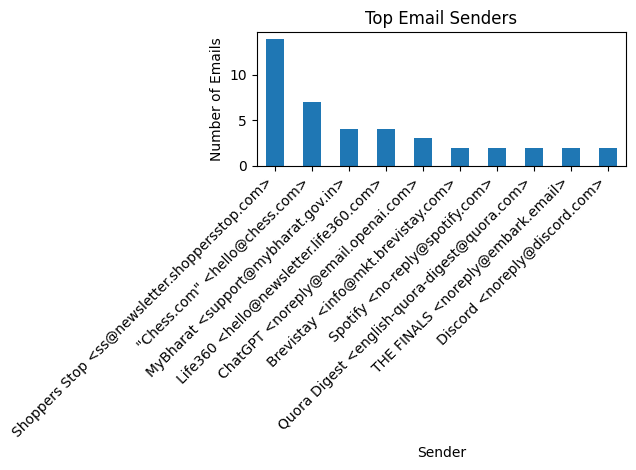

In [25]:
top_senders.plot(kind="bar")

plt.title("Top Email Senders")
plt.xlabel("Sender")
plt.ylabel("Number of Emails")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

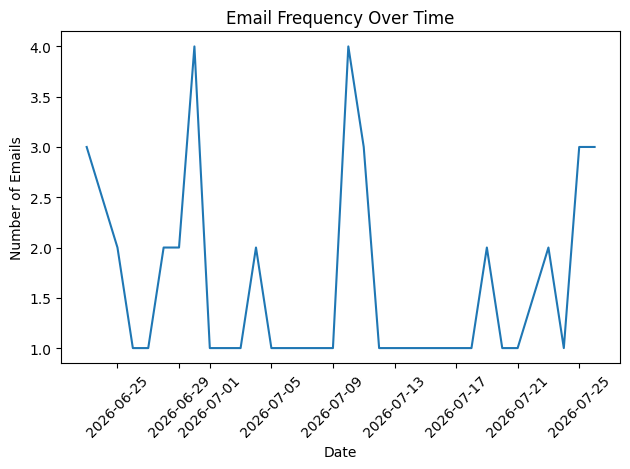

In [26]:
emails_per_day.plot(kind="line")

plt.title("Email Frequency Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Emails")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

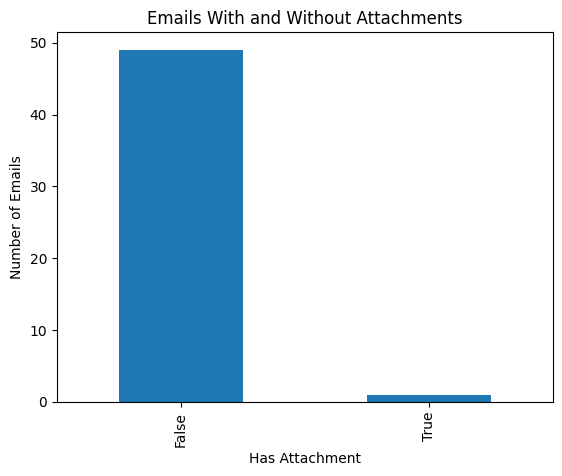

In [27]:
df["has_attachment"].value_counts().plot(kind="bar")

plt.title("Emails With and Without Attachments")
plt.xlabel("Has Attachment")
plt.ylabel("Number of Emails")

plt.show()

In [28]:
def classify_spam(labels):

    if "SPAM" in labels:
        return "Spam"

    return "Not Spam"


df["spam_status"] = df["labels"].apply(classify_spam)

In [29]:
print(
    df[
        ["subject", "from", "spam_status"]
    ].head(20)
)

                                              subject  \
0                         Your Basic Plan has expired   
1               Here’s What You’ve Missed This Month…   
2                           🛍️ Last HAUL. Best DEALS.   
3                                 🎉 We're Turning 10!   
4   Participate in the Nasha Mukt Yuva for Viksit ...   
5                                 🤑 MONTH END HAUL 🛍️   
6                            💥 50% OFF? That's a Yes.   
7                    You can now hit play on any song   
8        From _shahxdh and 1 other: 2 unread messages   
9              Before you go, we'd love your feedback   
10  Hello, SONALI here ● I need people for Work Fr...   
11                  It’s Been a Minute, lordhavmerci.   
12                            🚨 SALE's Back. Are You?   
13                          💥 More Deals. More Style.   
14                        Studio ready, from a selfie   
15  TURF TOWN TECHNOLOGIES PRIVATE LIMITED - Payme...   
16                    From fabc

spam_status
Not Spam    49
Spam         1
Name: count, dtype: int64


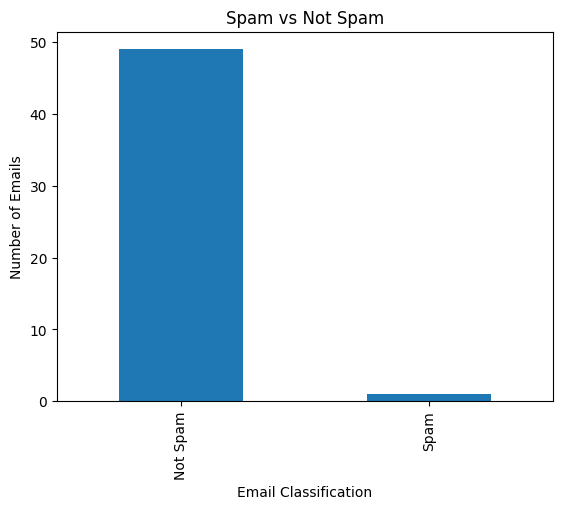

In [30]:
spam_counts = df["spam_status"].value_counts()

print(spam_counts)

spam_counts.plot(kind="bar")

plt.title("Spam vs Not Spam")
plt.xlabel("Email Classification")
plt.ylabel("Number of Emails")

plt.show()